# **Modern Portfolio Theory (MPT)**

Imagine you are asked a seemingly simple question: *Would you prefer Portfolio A or Portfolio B?*  
Modern Portfolio Theory (MPT) provides a rigorous and systematic framework to answer this question by explicitly modeling the trade-off between **expected return** and **risk**.

Originally developed by Harry Markowitz (1952), MPT is grounded in the assumption that investors are rational and risk-averse. Given two portfolios with the same expected return, a rational investor prefers the one with lower risk; conversely, given the same level of risk, the investor prefers the portfolio with the higher expected return.

**Portfolio Return**

Let $\mathbf{w} = (w_1, \dots, w_N)^\top$ denote the vector of portfolio weights, and let $\boldsymbol{\mu} = (\mu_1, \dots, \mu_N)^\top$ be the vector of expected asset returns.  
The expected return of the portfolio is given by the weighted average:

$$
\mathbb{E}[R_p] = \mathbf{w}^\top \boldsymbol{\mu}
= \sum_{i=1}^{N} w_i \mu_i,
\qquad \text{with } \sum_{i=1}^{N} w_i = 1.
$$

**Portfolio Risk**

Risk in the MPT framework is measured by the variance (or equivalently, the standard deviation) of portfolio returns.
Let $\boldsymbol{\Sigma}$ denote the covariance matrix of asset returns. The portfolio variance is:

$$
\mathrm{Var}(R_p) = \mathbf{w}^\top \boldsymbol{\Sigma} \mathbf{w},
$$

and the portfolio volatility is:

$$
\sigma_p = \sqrt{\mathbf{w}^\top \boldsymbol{\Sigma} \mathbf{w}}.
$$

A crucial implication of this formulation is that portfolio risk depends not only on individual asset variances, but also on the **covariances** between assets. As a result, combining imperfectly correlated assets allows for risk reduction through **diversification**, even when all individual assets are risky.

**Mean–Variance Optimization and the Efficient Frontier**

The central problem of Modern Portfolio Theory consists of minimizing portfolio variance for a given target expected return $\mu_p$:

$$
\begin{aligned}
\min_{\mathbf{w}} \quad & \mathbf{w}^\top \boldsymbol{\Sigma} \mathbf{w} \\
\text{s.t.} \quad
& \mathbf{w}^\top \boldsymbol{\mu} = \mu_p, \\
& \sum_{i=1}^{N} w_i = 1.
\end{aligned}
$$

Solving this optimization problem for different values of $\mu_p$ traces out the **efficient frontier**, which represents the set of portfolios offering the highest expected return for each level of risk. Any portfolio lying below the efficient frontier is suboptimal.

**Risk-Free Asset and Capital Market Line**

When a risk-free asset with return $r_f$ is introduced, the efficient set simplifies further. There exists a unique **tangency portfolio** that maximizes the Sharpe ratio:

$$
\text{Sharpe Ratio}
= \frac{\mathbb{E}[R_p] - r_f}{\sigma_p}.
$$

The combination of the risk-free asset and the tangency portfolio generates the **Capital Market Line (CML)**, described by:

$$
\mathbb{E}[R_p]
= r_f + \frac{\mathbb{E}[R_M] - r_f}{\sigma_M} \, \sigma_p,
$$

where $R_M$ and $\sigma_M$ denote the return and volatility of the market (tangency) portfolio.

In this notebook, the theoretical principles of Modern Portfolio Theory are implemented empirically using real market data. The analysis proceeds from data acquisition and exploratory statistics to portfolio optimization, efficient frontier construction, and Sharpe ratio maximization, providing a complete and transparent illustration of the MPT framework.


### **Libraries**

In [1]:
# Core numerical and data handling
import numpy as np
import pandas as pd

# Data acquisition
import yfinance as yf

# Optimization
from scipy import optimize

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

### **Data and Investment Universe**

The empirical analysis focuses on a stock-level investment universe composed of the constituents of the German **DAX index**. The DAX represents the major blue-chip companies listed on the Frankfurt Stock Exchange and provides a diversified exposure across multiple sectors of the German economy.

Constituent tickers are retrieved dynamically from Wikipedia in order to ensure transparency and reproducibility. Daily adjusted closing prices are obtained from Yahoo Finance and serve as the basis for return computation and portfolio optimization.

In [2]:
tickers = pd.read_html("https://it.wikipedia.org/wiki/DAX#Aziende", storage_options={"User-Agent": "Mozilla/5.0"})[0]['Simbolo'].tolist()
tickers = [t + ".DE" for t in tickers]

In [3]:
print(tickers)

['ADS.DE', 'AIR.DE', 'ALV.DE', 'BAS.DE', 'BAYN.DE', 'BEI.DE', 'BMW.DE', 'BNR.DE', 'CBK.DE', 'CON.DE', 'DTG.DE', 'DBK.DE', 'DB1.DE', 'DHL.DE', 'DTE.DE', 'EOAN.DE', 'FRE.DE', 'FME.DE', 'HNR1.DE', 'HEI.DE', 'HEN3.DE', 'IFX.DE', 'MBG.DE', 'MRK.DE', 'MTX.DE', 'MUV2.DE', 'PAH3.DE', 'P911.DE', 'QIA.DE', 'RHM.DE', 'RWE.DE', 'SAP.DE', 'SRT3.DE', 'SIE.DE', 'ENR.DE', 'SHL.DE', 'SY1.DE', 'VOW3.DE', 'VNA.DE', 'ZAL.DE']


In [4]:
prices = yf.download(tickers, "2020-01-01", "2026-01-01", auto_adjust=True)["Close"]

[*********************100%***********************]  40 of 40 completed


### **Data Cleaning and Return Construction**

Asset prices are converted into daily simple returns using percentage changes of adjusted closing prices.  
Missing values may arise due to changes in index composition or incomplete historical coverage. To ensure a consistent estimation of the covariance matrix, assets with insufficient data are implicitly excluded from the analysis.

Returns are computed without forward-filling missing observations in order to avoid introducing artificial serial dependence.

In [5]:
returns = prices.pct_change(fill_method=None).dropna()
returns.isna().sum()

Ticker
ADS.DE     0
AIR.DE     0
ALV.DE     0
BAS.DE     0
BAYN.DE    0
BEI.DE     0
BMW.DE     0
BNR.DE     0
CBK.DE     0
CON.DE     0
DB1.DE     0
DBK.DE     0
DHL.DE     0
DTE.DE     0
DTG.DE     0
ENR.DE     0
EOAN.DE    0
FME.DE     0
FRE.DE     0
HEI.DE     0
HEN3.DE    0
HNR1.DE    0
IFX.DE     0
MBG.DE     0
MRK.DE     0
MTX.DE     0
MUV2.DE    0
P911.DE    0
PAH3.DE    0
QIA.DE     0
RHM.DE     0
RWE.DE     0
SAP.DE     0
SHL.DE     0
SIE.DE     0
SRT3.DE    0
SY1.DE     0
VNA.DE     0
VOW3.DE    0
ZAL.DE     0
dtype: int64

In [6]:
display(returns.head())
display(prices.head())

Ticker,ADS.DE,AIR.DE,ALV.DE,BAS.DE,BAYN.DE,BEI.DE,BMW.DE,BNR.DE,CBK.DE,CON.DE,...,RHM.DE,RWE.DE,SAP.DE,SHL.DE,SIE.DE,SRT3.DE,SY1.DE,VNA.DE,VOW3.DE,ZAL.DE
Date,,,,,,,,,,,,,,,,,,,,,
2022-10-03,0.001010,0.003712,-0.001607,0.033838,0.011389,-0.025062,0.010573,0.016351,-0.006265,0.026986,...,0.020860,0.019053,0.008203,0.014002,-0.002767,0.054046,-0.006471,0.023413,0.000316,0.008403
2022-10-04,0.060504,0.061526,0.035038,0.033219,0.014389,0.024690,0.029973,0.037855,0.047971,0.039203,...,-0.044582,0.030382,0.043627,0.034521,0.053508,0.076780,0.028056,0.000440,0.038754,0.082843
2022-10-05,-0.026941,-0.014252,-0.006459,-0.009102,0.000103,0.001487,-0.018943,-0.015502,-0.038451,-0.055669,...,-0.006481,0.010837,-0.014349,-0.019376,-0.019564,-0.034296,0.002437,-0.046614,-0.013096,-0.052512
2022-10-06,-0.007655,-0.002785,-0.007103,-0.015388,-0.019424,0.003465,0.006996,-0.013893,-0.000272,0.014900,...,-0.015003,-0.025929,0.009858,-0.001317,0.008634,0.021972,-0.009723,-0.012454,0.021293,0.032011
2022-10-07,-0.051699,-0.008592,-0.003880,-0.013933,-0.005974,-0.002960,-0.003752,-0.029117,0.004082,0.020213,...,0.023510,0.000512,-0.015550,-0.015388,-0.023587,-0.048250,-0.018164,-0.037366,-0.015863,-0.044907


Ticker,ADS.DE,AIR.DE,ALV.DE,BAS.DE,BAYN.DE,BEI.DE,BMW.DE,BNR.DE,CBK.DE,CON.DE,...,RHM.DE,RWE.DE,SAP.DE,SHL.DE,SIE.DE,SRT3.DE,SY1.DE,VNA.DE,VOW3.DE,ZAL.DE
Date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,278.611328,124.770157,163.322479,46.920929,62.330235,101.082001,52.578621,41.567234,5.482380,87.871338,...,92.809875,22.989527,110.763008,38.273045,89.963326,190.716080,88.092850,30.414280,112.096634,45.779999
2020-01-03,278.993591,125.274719,161.515991,46.220100,61.533302,101.082001,51.941048,40.944923,5.384729,86.044464,...,92.272102,22.887201,109.364861,38.264046,88.234428,189.139893,88.187012,30.527340,109.699440,45.270000
2020-01-06,276.795624,124.714119,160.520569,45.533016,60.821156,101.416862,51.749779,40.663605,5.216399,85.063087,...,90.972496,22.554638,108.547745,38.201057,87.824951,186.578613,87.283119,30.433128,109.687012,44.910000
2020-01-07,281.669312,123.424751,160.889236,45.553631,61.151798,101.177666,52.578621,41.158043,5.306609,86.905060,...,92.720238,23.066273,109.038025,38.367538,88.386078,188.647354,86.680519,30.596437,109.339233,45.529999
2020-01-08,289.409821,125.667130,160.962997,45.161995,62.737186,101.608215,52.713223,41.661007,5.420070,88.580948,...,93.033951,23.168604,109.691696,38.534027,88.750069,190.913086,86.624016,30.759752,109.811226,46.189999


### **Exploratory Data Analysis**

Before proceeding to portfolio optimization, an exploratory analysis of asset returns is conducted.  
In particular, the correlation structure across assets is examined, as cross-asset dependence plays a central role in diversification benefits and overall portfolio risk.

The correlation matrix provides an initial qualitative assessment of the potential gains from combining different assets within a portfolio.

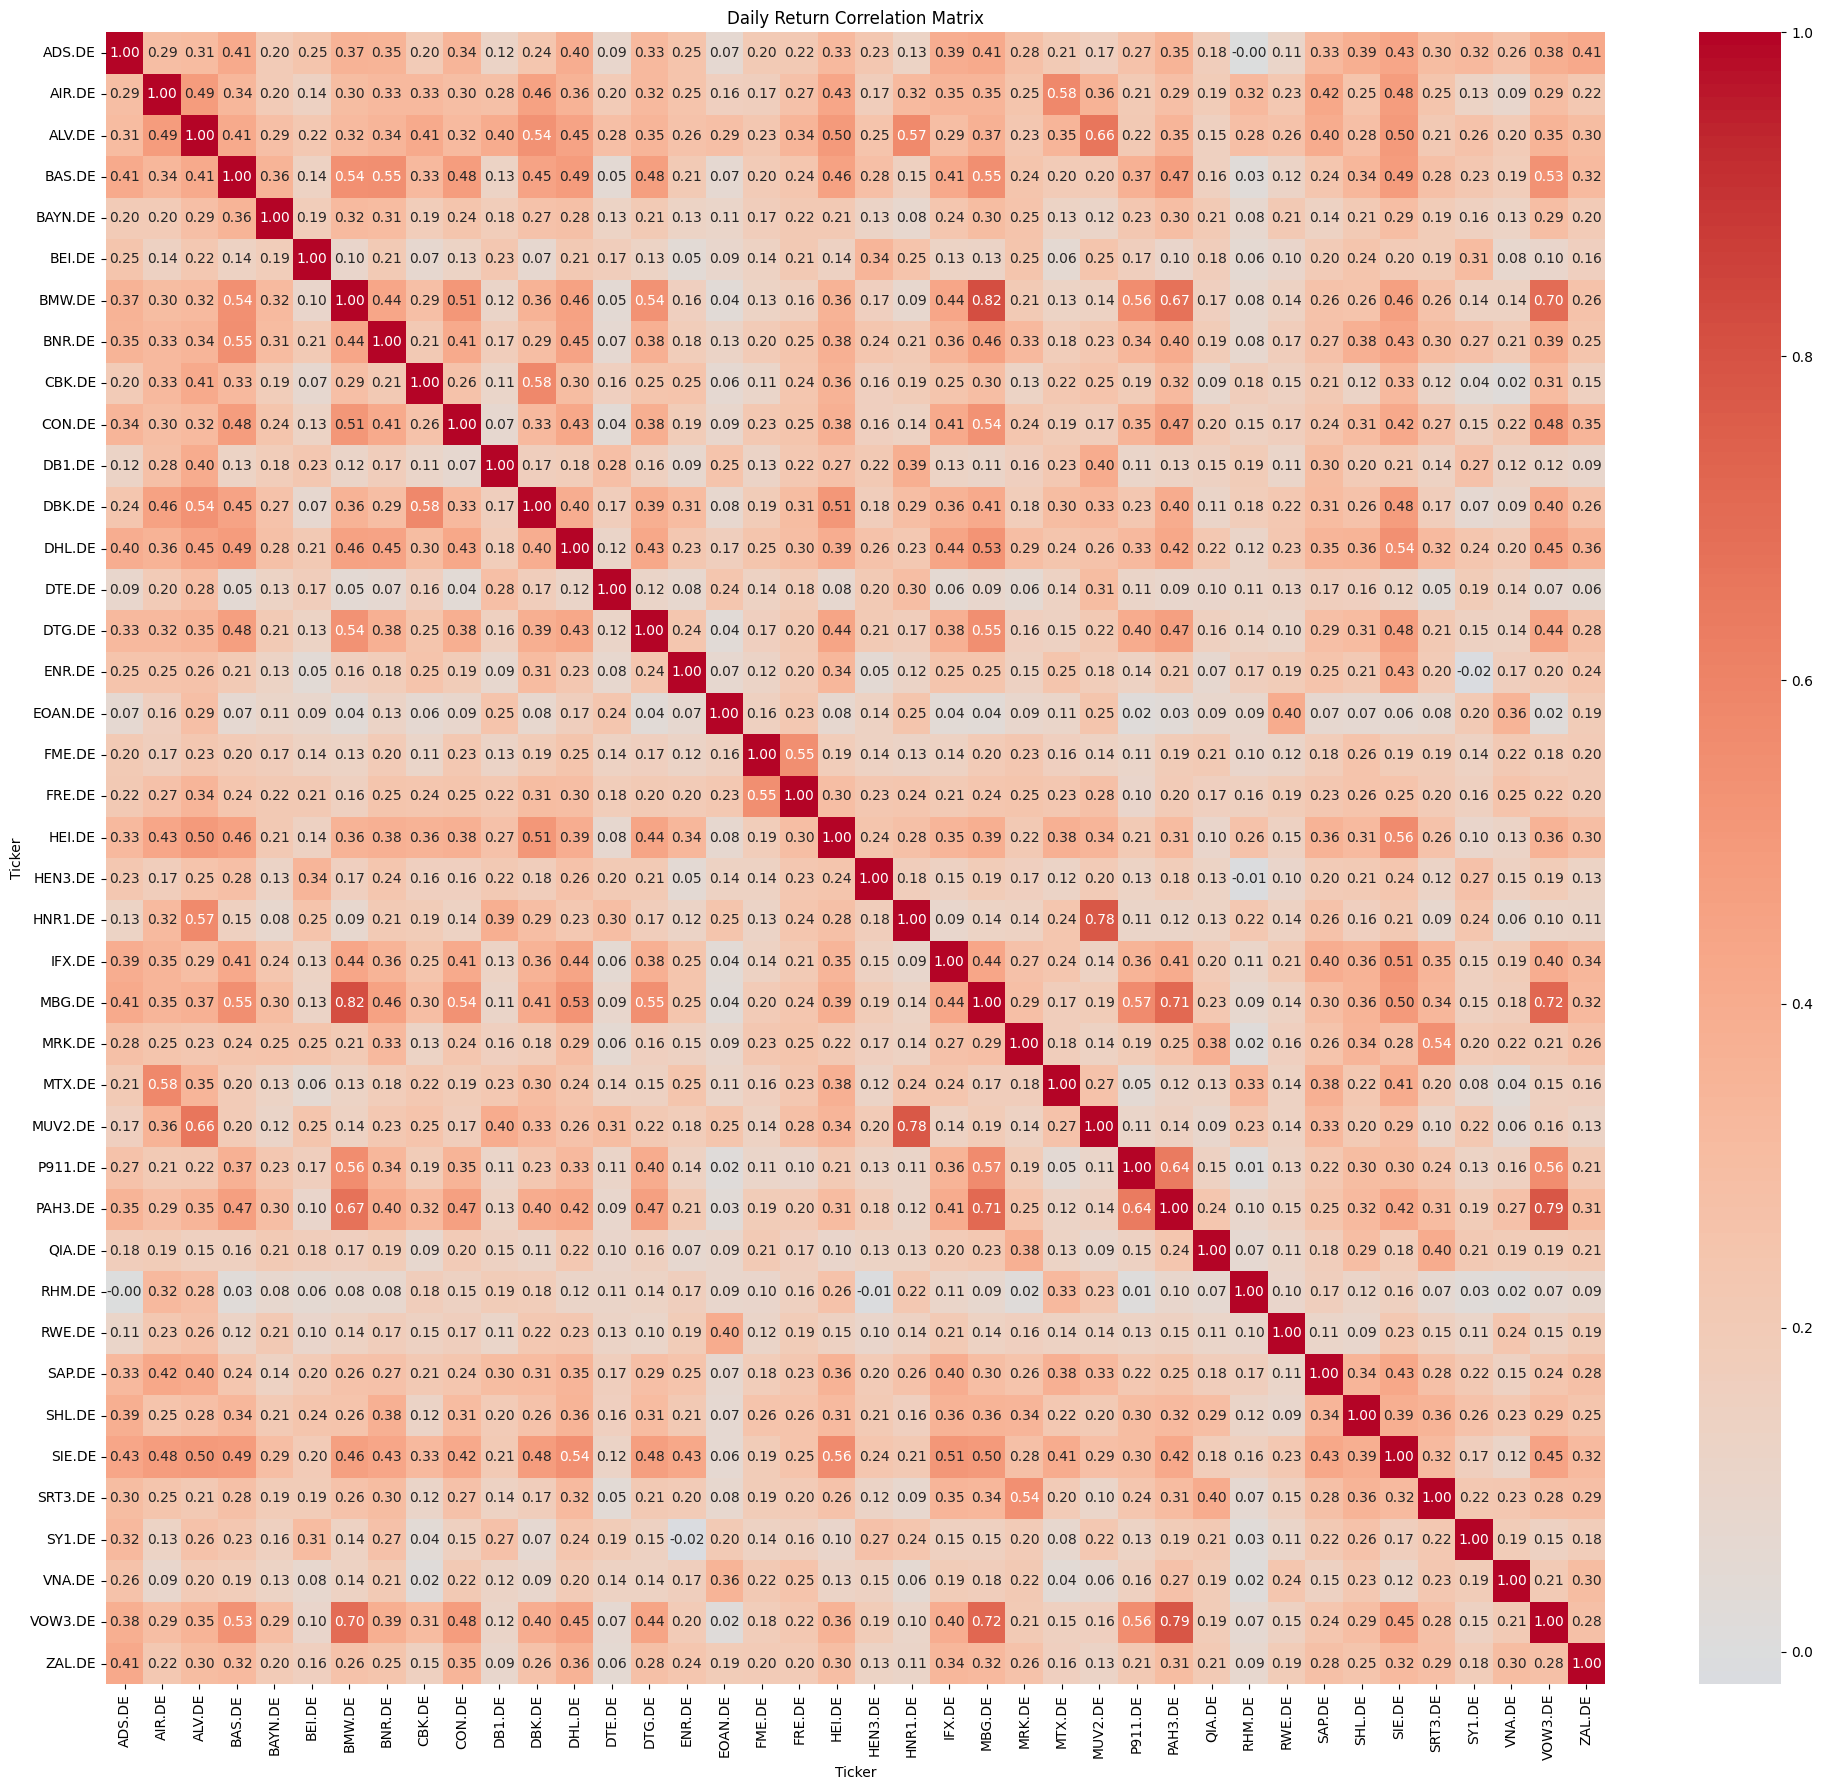

In [7]:
# --------------------------------------------------
# Quick exploratory analysis: correlation
# --------------------------------------------------
corr_matrix = returns.corr()

plt.figure(figsize=(20, 18))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Daily Return Correlation Matrix")
plt.tight_layout()
plt.show()

### **Summary Statistics**

This section reports key descriptive statistics for daily asset returns, including mean, volatility, skewness, and kurtosis.  
Annualized measures of expected return and volatility are computed assuming 252 trading days per year.

These statistics provide a preliminary characterization of the risk–return profiles of individual assets prior to portfolio aggregation.

In [8]:
# --------------------------------------------------
# Summary statistics (DAILY returns -> ANNUALIZED with 252)
# --------------------------------------------------
T = 252  # Trading days in a year
rf_annual = 0.00  # risk-free rate (changable)
rf_daily = (1 + rf_annual)**(1/T) - 1

summary_stats = pd.DataFrame({
    "Mean (Daily)": returns.mean(),
    "Vol (Daily)": returns.std(),
    "Skew (Daily)": returns.skew(),
    "Kurt (Daily)": returns.kurt(),  # excess kurtosis
})

summary_stats["Return (Ann.)"] = (1 + summary_stats["Mean (Daily)"])**T - 1
summary_stats["Vol (Ann.)"] = summary_stats["Vol (Daily)"] * np.sqrt(T)

# Sharpe (annualized)
excess_mean_daily = summary_stats["Mean (Daily)"] - rf_daily
summary_stats["Sharpe (Ann.)"] = (excess_mean_daily / summary_stats["Vol (Daily)"]) * np.sqrt(T)

display(
    summary_stats
    .sort_values(by="Vol (Ann.)", ascending=False)
    .style.format({
        "Mean (Daily)": "{:.4%}",
        "Vol (Daily)": "{:.4%}",
        "Return (Ann.)": "{:.2%}",
        "Vol (Ann.)": "{:.2%}",
        "Sharpe (Ann.)": "{:.2f}",
        "Skew (Daily)": "{:.2f}",
        "Kurt (Daily)": "{:.2f}",
    })
)

,Mean (Daily),Vol (Daily),Skew (Daily),Kurt (Daily),Return (Ann.),Vol (Ann.),Sharpe (Ann.)
Ticker,,,,,,,
ENR.DE,0.3423%,3.4488%,-2.75,33.17,136.60%,54.75%,1.58
SRT3.DE,0.0060%,2.8904%,-0.22,7.14,1.52%,45.88%,0.03
ZAL.DE,0.0499%,2.8057%,0.88,4.29,13.39%,44.54%,0.28
RHM.DE,0.3025%,2.4846%,0.41,3.58,114.05%,39.44%,1.93
IFX.DE,0.0948%,2.3385%,0.44,2.61,26.95%,37.12%,0.64
CBK.DE,0.2263%,2.2920%,0.53,6.54,76.75%,36.38%,1.57
CON.DE,0.0868%,2.2181%,-1.53,25.41,24.45%,35.21%,0.62
ADS.DE,0.0617%,2.1689%,0.79,15.37,16.82%,34.43%,0.45
VNA.DE,0.0315%,2.1570%,0.17,2.76,8.26%,34.24%,0.23


### **Mean–Variance Optimization Framework**

Portfolio optimization is conducted within the classical mean–variance framework.  
Expected returns are estimated as sample means of historical returns, while risk is measured through the annualized covariance matrix of asset returns.

The optimization problem is solved under a long-only constraint, reflecting realistic investment restrictions faced by many institutional and retail investors.

In [9]:
# Annualized inputs for optimization
cov_matrix = returns.cov() * T
mean_returns = returns.mean() * T

In [10]:
def portfolio_risk(weights, cov):
    return np.sqrt(weights @ cov @ weights)

def portfolio_return(weights, mu):
    return weights @ mu

def constraint_sum_to_1(weights):
    return np.sum(weights) - 1

def constraint_return_target(weights, mu, target):
    return portfolio_return(weights, mu) - target

In [11]:
bounds = tuple((0, 1) for _ in range(len(mean_returns)))  # long-only
initial_guess = np.repeat(1/len(mean_returns), len(mean_returns))

### **Efficient Frontier Estimation**

By solving the constrained optimization problem for a grid of target expected returns, the efficient frontier is obtained.  
Each point on the frontier represents a portfolio that minimizes variance for a given level of expected return.

The efficient frontier summarizes the optimal risk–return trade-offs available within the chosen investment universe.

In [12]:
# Efficient frontier
target_returns = np.linspace(mean_returns.min(), mean_returns.max(), 100)
efficient_frontier_volatility = []
efficient_frontier_weights = []

for tr in target_returns:
    constraints = [
        {"type": "eq", "fun": constraint_sum_to_1},
        {"type": "eq", "fun": constraint_return_target, "args": (mean_returns.values, tr)},
    ]
    result = optimize.minimize(
        portfolio_risk,
        initial_guess,
        args=(cov_matrix.values,),
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
    )
    efficient_frontier_volatility.append(result.fun)   # già è sigma (non varianza)
    efficient_frontier_weights.append(result.x)

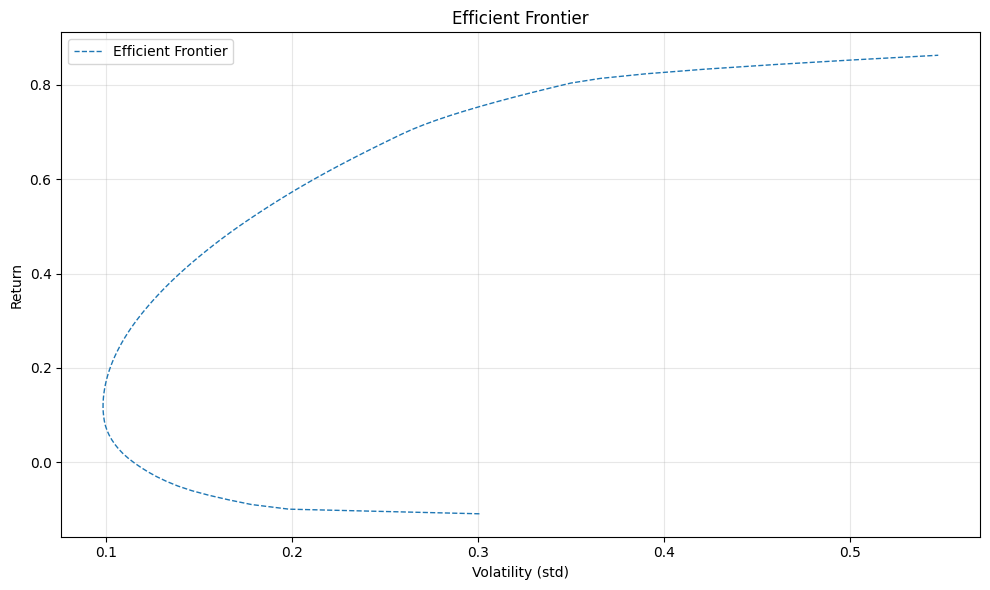

In [13]:
# Plot
plt.figure(figsize=(10, 6))
plt.plot(efficient_frontier_volatility,
         target_returns[:len(efficient_frontier_volatility)],
         linestyle="--", linewidth=1, label="Efficient Frontier")
plt.xlabel("Volatility (std)")
plt.ylabel("Return")
plt.title("Efficient Frontier")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### **Introducing a Risk-Free Asset**

The analysis is extended by introducing a risk-free asset with a constant annual return.  
The presence of a risk-free asset alters the efficient set of portfolios and allows investors to achieve superior risk–return combinations through leverage or partial investment in the risk-free asset.

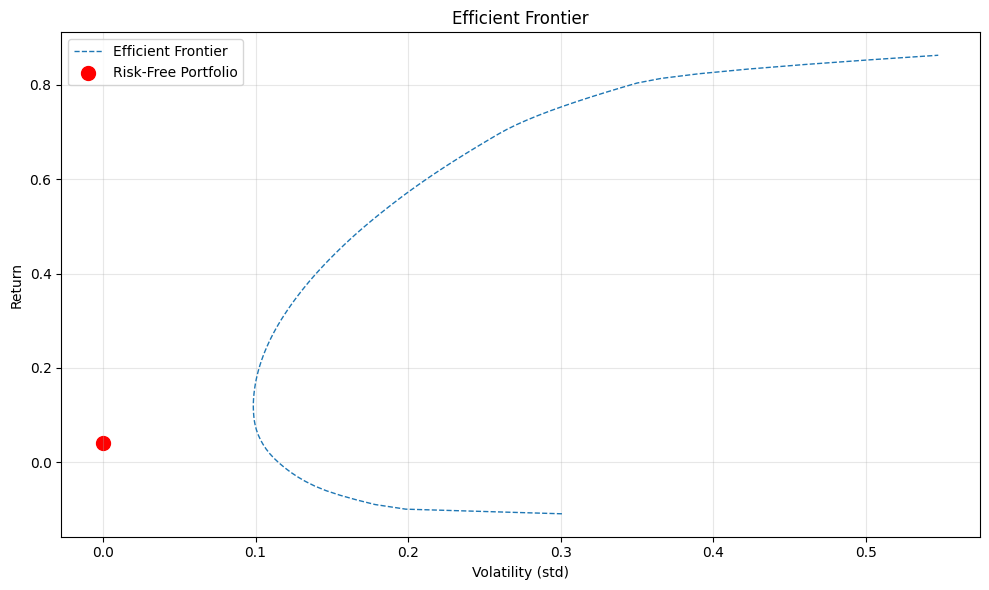

In [14]:
risk_free_rate = 0.04 # annual risk-free rate

# Plot
plt.figure(figsize=(10, 6))
plt.plot(efficient_frontier_volatility,
         target_returns[:len(efficient_frontier_volatility)],
         linestyle="--", linewidth=1, label="Efficient Frontier")
plt.scatter(0, risk_free_rate, color='red', s=100, marker='o', label='Risk-Free Portfolio')
plt.xlabel("Volatility (std)")
plt.ylabel("Return")
plt.title("Efficient Frontier")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### **Tangency Portfolio (Maximum Sharpe Ratio)**

The tangency portfolio is obtained by maximizing the Sharpe ratio.  
Since numerical optimizers are formulated as minimization problems, the negative Sharpe ratio is minimized instead.  
In conclusion, we minimize the negative SR because optimizers minimize by default.

In [15]:
def negative_sharpe_ratio(weights, mu, cov, rf):
    port_ret = portfolio_return(weights, mu)
    port_vol = portfolio_risk(weights, cov)
    return -(port_ret - rf) / port_vol

constraints_sr = [{"type": "eq", "fun": constraint_sum_to_1}]

result = optimize.minimize(
    fun=negative_sharpe_ratio,
    x0=initial_guess,
    args=(mean_returns.values, cov_matrix.values, risk_free_rate),
    method="SLSQP",
    bounds=bounds,
    constraints=constraints_sr,
)

In [16]:
optimal_weights = result.x
market_portfolio_return = portfolio_return(optimal_weights, mean_returns)
market_portfolio_volatility = portfolio_risk(optimal_weights, cov_matrix)
max_sharpe_ratio = -result.fun # since we minimized the negative Sharpe Ratio

In [17]:
cml_volatility = np.linspace(0, market_portfolio_volatility * 2, 100)
cml_returns = risk_free_rate + (market_portfolio_return - risk_free_rate) * (cml_volatility / market_portfolio_volatility)

### **Monte Carlo Simulation of Random Portfolios**

To provide additional intuition, a large number of random portfolios is generated using Monte Carlo simulation.  
These portfolios serve as a benchmark against which the efficient frontier and the Capital Market Line can be visually compared.

The simulation highlights how optimal portfolios systematically dominate randomly constructed allocations in terms of risk–return efficiency.

In [18]:
eff_idx = 95
cml_idx = 30

def generate_random_portfolios(num_assets, num_portfolios=1000):
    # Generate random portfolios
    portfolios = []
    for _ in range(num_portfolios):
        # Generate random weights
        weights = np.random.random(num_assets)
        # Normalize weights to sum to 1
        weights /= np.sum(weights)
        portfolios.append(weights)
    return np.array(portfolios)

def generate_random_portfolios(num_assets, num_portfolios=1000, dispersion=0.01):
    """
    Generate random portfolio weights with more dispersion.

    Parameters:
        num_assets (int): Number of assets in each portfolio.
        num_portfolios (int): Number of portfolios to generate.
        dispersion (float): Dispersion parameter for Dirichlet distribution (< 1 for more dispersion).

    Returns:
        np.ndarray: Array of portfolio weights (shape: num_portfolios x num_assets).
    """
    # Use the Dirichlet distribution to generate weights with specified dispersion
    portfolios = np.random.dirichlet([dispersion] * num_assets, num_portfolios)
    return portfolios


# Example usage
num_assets = len(mean_returns)  # Replace with the actual number of assets
portfolios = generate_random_portfolios(num_assets)
# print(portfolios[0:2])  # Show the first few portfolios

random_vols = np.sqrt(np.einsum('ij,jk,ik->i', portfolios, cov_matrix, portfolios))
random_returns = np.dot(portfolios, mean_returns)

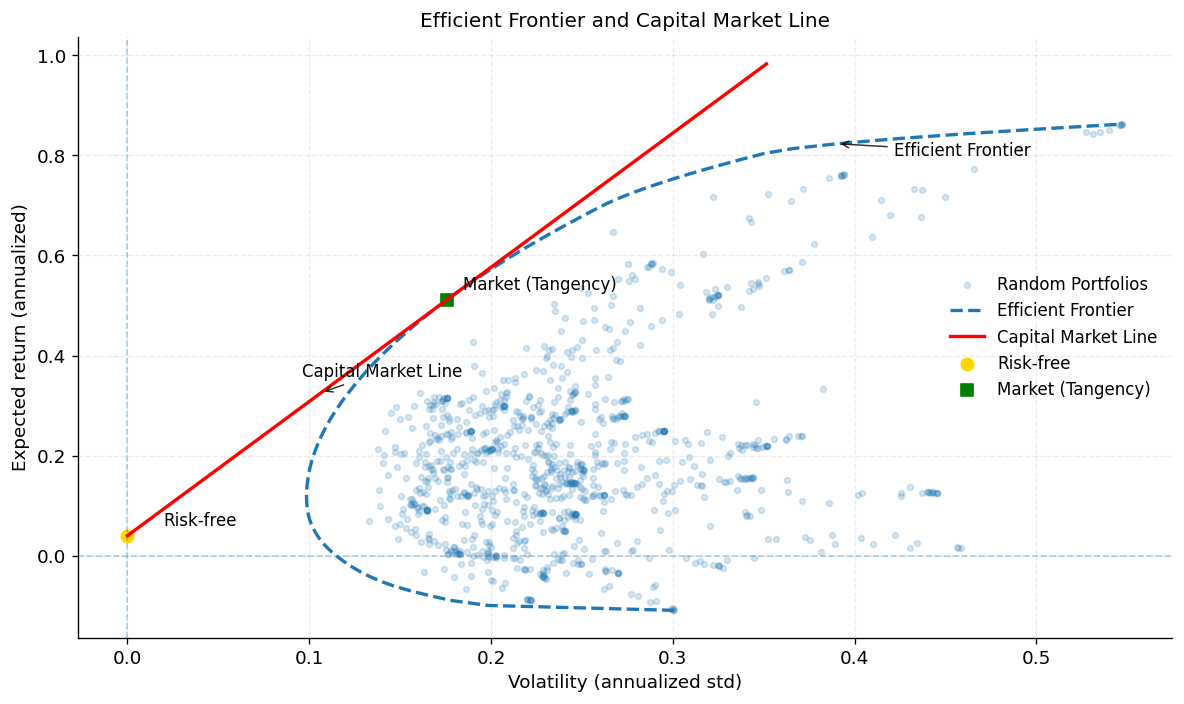

In [19]:
# --------------------------------------------------
# Plot
# --------------------------------------------------

risk_free_rate = 0.04  # Annual risk-free rate

# Basic styling (clean, paper-like)
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(10, 6))

# Random portfolios cloud (very light)
ax.scatter(random_vols, random_returns, s=12, alpha=0.18, label="Random Portfolios")

# Efficient Frontier
target_ok = target_returns[:len(efficient_frontier_volatility)]
ax.plot(
    efficient_frontier_volatility,
    target_ok,
    linestyle="--",
    linewidth=2.0,
    label="Efficient Frontier"
)

# Capital Market Line
ax.plot(
    cml_volatility,
    cml_returns,
    linewidth=2.0,
    label="Capital Market Line",
    color='red'
)

# Risk-free and Market (Tangency) portfolio points
ax.scatter(0.0, risk_free_rate, s=55, marker="o", label="Risk-free", color='gold')
ax.scatter(market_portfolio_volatility, market_portfolio_return, s=60, marker="s", label="Market (Tangency)", color='green')

# Reference axes at zero (subtle)
ax.axhline(0, linewidth=1.0, linestyle="--", alpha=0.35)
ax.axvline(0, linewidth=1.0, linestyle="--", alpha=0.35)

# Discrete annotations (small, neutral arrows)
ax.annotate(
    "Efficient Frontier",
    xy=(efficient_frontier_volatility[eff_idx], target_ok[eff_idx]),
    xytext=(efficient_frontier_volatility[eff_idx] * 1.08, target_ok[eff_idx] * 0.97),
    arrowprops=dict(arrowstyle="->", lw=0.9, alpha=0.8),
    fontsize=10
)

ax.annotate(
    "Capital Market Line",
    xy=(cml_volatility[cml_idx], cml_returns[cml_idx]),
    xytext=(cml_volatility[cml_idx] * 0.9, cml_returns[cml_idx] * 1.1),
    arrowprops=dict(arrowstyle="->", lw=0.9, alpha=0.8),
    fontsize=10
)

ax.annotate(
    "Risk-free",
    xy=(0.0, risk_free_rate),
    xytext=(0.02, risk_free_rate + 0.02),
    fontsize=10,
)

ax.annotate(
    "Market (Tangency)",
    xy=(market_portfolio_volatility, market_portfolio_return),
    xytext=(market_portfolio_volatility * 1.05, market_portfolio_return + 0.02),
    fontsize=10
)

# Labels & title
ax.set_xlabel("Volatility (annualized std)")
ax.set_ylabel("Expected return (annualized)")
ax.set_title("Efficient Frontier and Capital Market Line")

# Legend (clean placement)
ax.legend(frameon=False, loc="best")

plt.tight_layout()
plt.show()

### **Final Remarks and Limitations**

While Modern Portfolio Theory provides a powerful and elegant framework, it relies on several strong assumptions, including stable return distributions, rational investor behavior, and reliable estimates of expected returns and covariances.

In practice, estimation error, time-varying correlations, and non-normal return distributions may significantly affect portfolio performance.  
Despite these limitations, MPT remains a foundational tool in quantitative finance and serves as a benchmark for more advanced portfolio construction techniques.